In [ ]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
#load dataset - remember to upload the file when you run this model again
df = pd.read_csv('/content/Final_Augmented_dataset_Diseases_and_Symptoms.csv')

In [ ]:
#check the dataset columns
df.shape
df.head()

,diseases,anxiety and nervousness,depression,shortness of breath,depressive or psychotic symptoms,sharp chest pain,dizziness,insomnia,abnormal involuntary movements,chest tightness,...,stuttering or stammering,problems with orgasm,nose deformity,lump over jaw,sore in nose,hip weakness,back swelling,ankle stiffness or tightness,ankle weakness,neck weakness
0,panic disorder,1,0,1,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,panic disorder,0,0,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,panic disorder,1,1,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,panic disorder,1,0,0,1,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
4,panic disorder,1,1,0,0,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
print(df["diseases"].unique())

['panic disorder' 'vocal cord polyp' 'turner syndrome' 'cryptorchidism'
 'poisoning due to ethylene glycol' 'atrophic vaginitis'
 'fracture of the hand' 'cellulitis or abscess of mouth'
 'eye alignment disorder' 'headache after lumbar puncture'
 'pyloric stenosis' 'salivary gland disorder' 'osteochondrosis'
 'injury to the knee' 'metabolic disorder' 'vaginitis'
 'sick sinus syndrome' 'tinnitus of unknown cause' 'glaucoma'
 'eating disorder' 'transient ischemic attack' 'pyelonephritis'
 'rotator cuff injury' 'chronic pain disorder' 'problem during pregnancy'
 'liver cancer' 'atelectasis' 'injury to the hand' 'choledocholithiasis'
 'injury to the hip' 'cirrhosis' 'thoracic aortic aneurysm'
 'subdural hemorrhage' 'diabetic retinopathy' 'fibromyalgia'
 'ischemia of the bowel' 'fetal alcohol syndrome' 'peritonitis'
 'injury to the abdomen' 'acute pancreatitis' 'thrombophlebitis' 'asthma'
 'foreign body in the vagina' 'restless leg syndrome' 'emphysema'
 'cysticercosis' 'induced abortion' 't

In [ ]:
sorted(df["diseases"].unique())

['abdominal aortic aneurysm',
 'abdominal hernia',
 'abscess of nose',
 'abscess of the lung',
 'abscess of the pharynx',
 'acanthosis nigricans',
 'acariasis',
 'achalasia',
 'acne',
 'actinic keratosis',
 'acute bronchiolitis',
 'acute bronchitis',
 'acute bronchospasm',
 'acute fatty liver of pregnancy (aflp)',
 'acute glaucoma',
 'acute kidney injury',
 'acute otitis media',
 'acute pancreatitis',
 'acute respiratory distress syndrome (ards)',
 'acute sinusitis',
 'acute stress reaction',
 'adhesive capsulitis of the shoulder',
 'adjustment reaction',
 'adrenal adenoma',
 'adrenal cancer',
 'alcohol abuse',
 'alcohol intoxication',
 'alcohol withdrawal',
 'alcoholic liver disease',
 'allergy',
 'allergy to animals',
 'alopecia',
 'alzheimer disease',
 'amblyopia',
 'amyloidosis',
 'amyotrophic lateral sclerosis (als)',
 'anal fissure',
 'anal fistula',
 'anemia',
 'anemia due to chronic kidney disease',
 'anemia due to malignancy',
 'anemia of chronic disease',
 'angina',
 'ankylos

In [ ]:
#these are 5 selected disease for this prototype model
selected_diseases = [
    "common cold",
    "asthma",
    "flu",
    "acute sinusitis",
    "tuberculosis" #added to test the infectious disease
]

In [ ]:
df_filtered = df[df["diseases"].isin(selected_diseases)]

In [ ]:
print(df_filtered["diseases"].unique())
print(len(df_filtered["diseases"].unique()))

['asthma' 'acute sinusitis' 'tuberculosis' 'common cold' 'flu']
5


In [ ]:
df_filtered["diseases"].value_counts()

,count
diseases,
acute sinusitis,906
common cold,905
asthma,904
flu,679
tuberculosis,23


In [ ]:
X = df_filtered.drop(columns=["diseases"])
y = df_filtered["diseases"]

In [ ]:
X.shape, y.shape

((3417, 377), (3417,))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
lr_model = LogisticRegression(
    max_iter=1000,
    multi_class="auto"
)

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

lr_acc = accuracy_score(y_test, lr_pred)
print("Logistic Regression Accuracy:", lr_acc)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Logistic Regression Accuracy: 0.9707602339181286


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_acc = accuracy_score(y_test, rf_pred)
print("Random Forest Accuracy:", rf_acc)

Random Forest Accuracy: 0.9692982456140351


In [ ]:
print("Random Forest Accuracy:", rf_acc)
print("Logistic Regression Accuracy:", lr_acc)

Random Forest Accuracy: 0.9692982456140351
Logistic Regression Accuracy: 0.9707602339181286


In [ ]:
print(classification_report(y_test, rf_pred))

                 precision    recall  f1-score   support

acute sinusitis       0.97      0.99      0.98       181
         asthma       0.99      0.98      0.99       181
    common cold       0.94      0.96      0.95       181
            flu       0.98      0.93      0.95       136
   tuberculosis       1.00      1.00      1.00         5

       accuracy                           0.97       684
      macro avg       0.98      0.97      0.97       684
   weighted avg       0.97      0.97      0.97       684



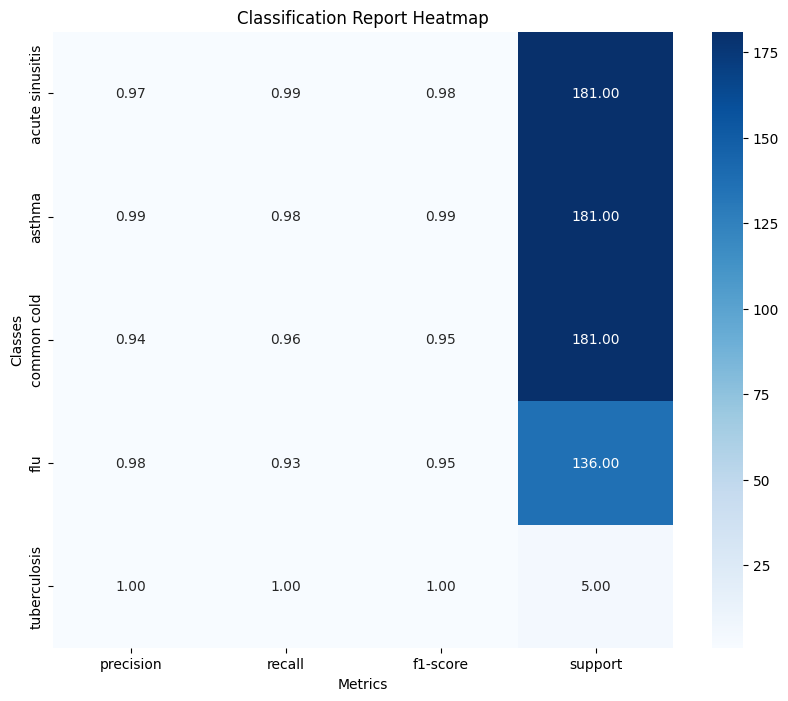

In [ ]:
report = classification_report(y_test, rf_pred, output_dict=True)
df_report = pd.DataFrame(report).transpose()

plt.figure(figsize=(10, 8))
sns.heatmap(df_report.iloc[:-3, :].astype(float), annot=True, cmap='Blues', fmt='.2f')
plt.title('Classification Report Heatmap')
plt.ylabel('Classes')
plt.xlabel('Metrics')
plt.show()

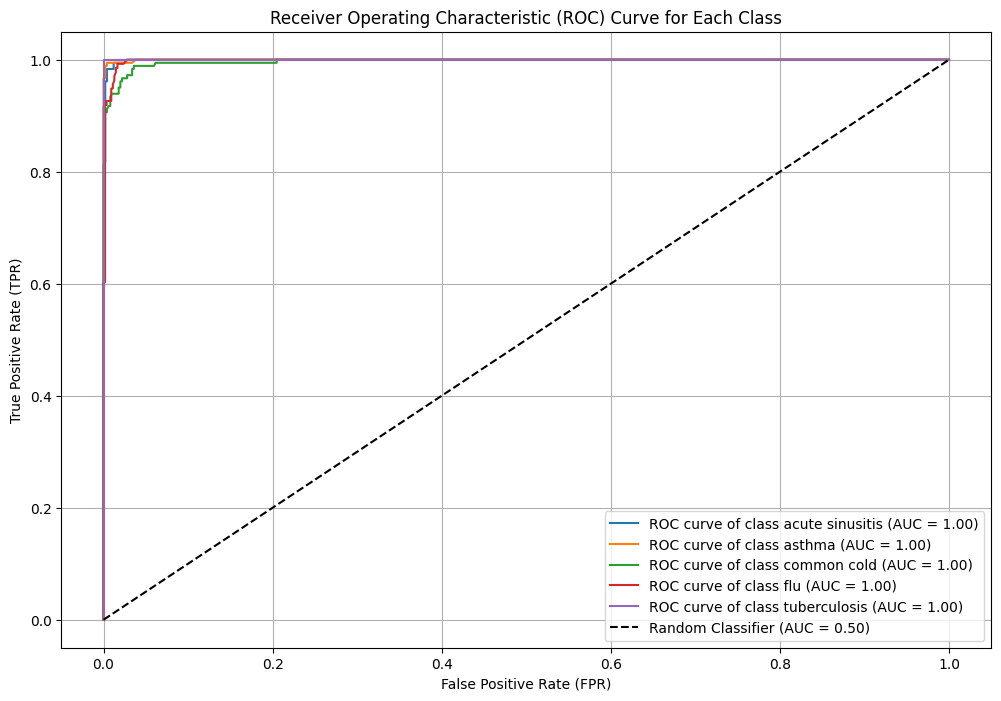

In [ ]:
  from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import roc_curve, auc

# Get predicted probabilities for each class
y_pred_proba = rf_model.predict_proba(X_test)

# Binarize the true labels for multi-class ROC
label_binarizer = LabelBinarizer()
y_test_binarized = label_binarizer.fit_transform(y_test)
classes = label_binarizer.classes_

plt.figure(figsize=(12, 8))

# Plot ROC curve for each class
for i in range(len(classes)):
    fpr, tpr, _ = roc_curve(y_test_binarized[:, i], y_pred_proba[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'ROC curve of class {classes[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve for Each Class')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
confusion_matrix(y_test, rf_pred)

array([[180,   1,   0,   0,   0],
       [  1, 178,   2,   0,   0],
       [  4,   0, 174,   3,   0],
       [  1,   0,   9, 126,   0],
       [  0,   0,   0,   0,   5]])

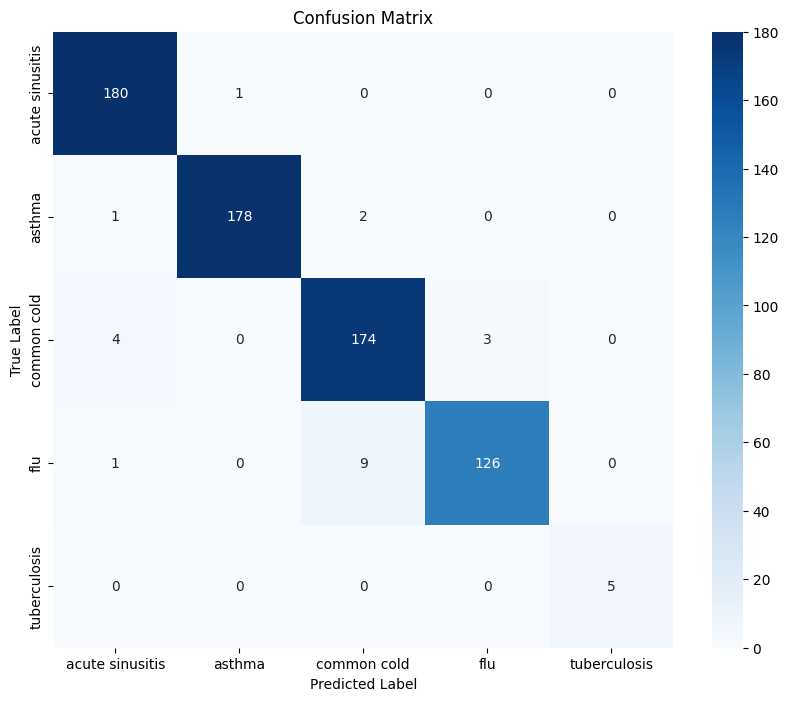

In [ ]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues',
            xticklabels=rf_model.classes_,
            yticklabels=rf_model.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
joblib.dump(rf_model, "disease_model.pkl")
joblib.dump(X.columns.tolist(), "symptom_columns.pkl")

['symptom_columns.pkl']